# Mount Google Drive and Link Datasets

In [ ]:
rm -rf /content/data

In [ ]:
# Create base data directory
!mkdir -p /content/data

# Link the *inner* ISIC2019_merged folder directly (the one that contains 7 class folders)
!ln -s "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged" /content/data/ISIC2019

# Link the unlabeled Fitzpatrick target domain
!ln -s "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled/dummy" /content/data/Fitzpatrick17k

# Link the labeled Fitzpatrick test subset
!ln -s "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected" /content/data/Fitzpatrick17k_test


In [ ]:
!rm -rf /content/data/ISIC2019/ISIC2019_merged
!rm -rf /content/data/Fitzpatrick17k/dummy
!rm -rf /content/data/Fitzpatrick17k_test/fitz_selected

# Install Dependencies

In [ ]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
!pip install scikit-learn pandas tqdm matplotlib seaborn


Looking in indexes: https://download.pytorch.org/whl/cu118


# Run ADDA Training

In [ ]:
!python "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/adda_mobilenetV2.py" \
  --source-dir /content/data/ISIC2019 \
  --target-dir /content/data/Fitzpatrick17k \
  --test-dir /content/data/Fitzpatrick17k_test \
  --out-dir /content/drive/MyDrive/Colab\ Results/ADDA_MOBILENETV2 \
  --batch-size 16 \
  --pretrain-epochs 20 \
  --adapt-epochs 40 \
  --use-focal


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth
100% 13.6M/13.6M [00:00<00:00, 158MB/s]
>>> Pretraining source encoder + classifier
Pretrain Ep 1/20: 100% 1567/1567 [44:53<00:00,  1.72s/it, acc=0.69, loss=0.062]
Pretrain epoch 1 loss=0.1167 acc=0.6897
Pretrain Ep 2/20: 100% 1

# View Evaluation Results

,precision,recall,f1-score,support
ak,0.060345,0.080000,0.068796,175.000000
bcc,0.263027,0.212000,0.234773,500.000000
bkl,0.057143,0.086957,0.068966,69.000000
df,0.000000,0.000000,0.000000,79.000000
mel,0.236220,0.060000,0.095694,500.000000
nv,0.120777,0.605932,0.201408,236.000000
scc,0.000000,0.000000,0.000000,500.000000
accuracy,0.145216,0.145216,0.145216,0.145216
macro avg,0.105359,0.149270,0.095662,2059.000000
weighted avg,0.142123,0.145216,0.111493,2059.000000


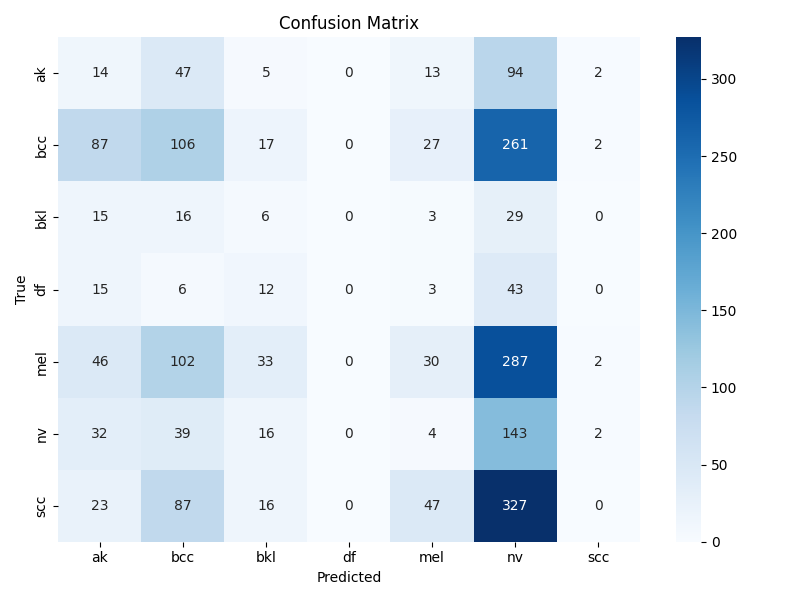

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Load classification report
report_path = "/content/drive/MyDrive/Colab Results/ADDA_MOBILENETV2/classification_report.csv"
df = pd.read_csv(report_path, index_col=0)
display(df)

# Show confusion matrix
cm_path = "/content/drive/MyDrive/Colab Results/ADDA_MOBILENETV2/confusion_matrix.png"
display(Image(filename=cm_path))


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Showing predictions for 3 images per class...


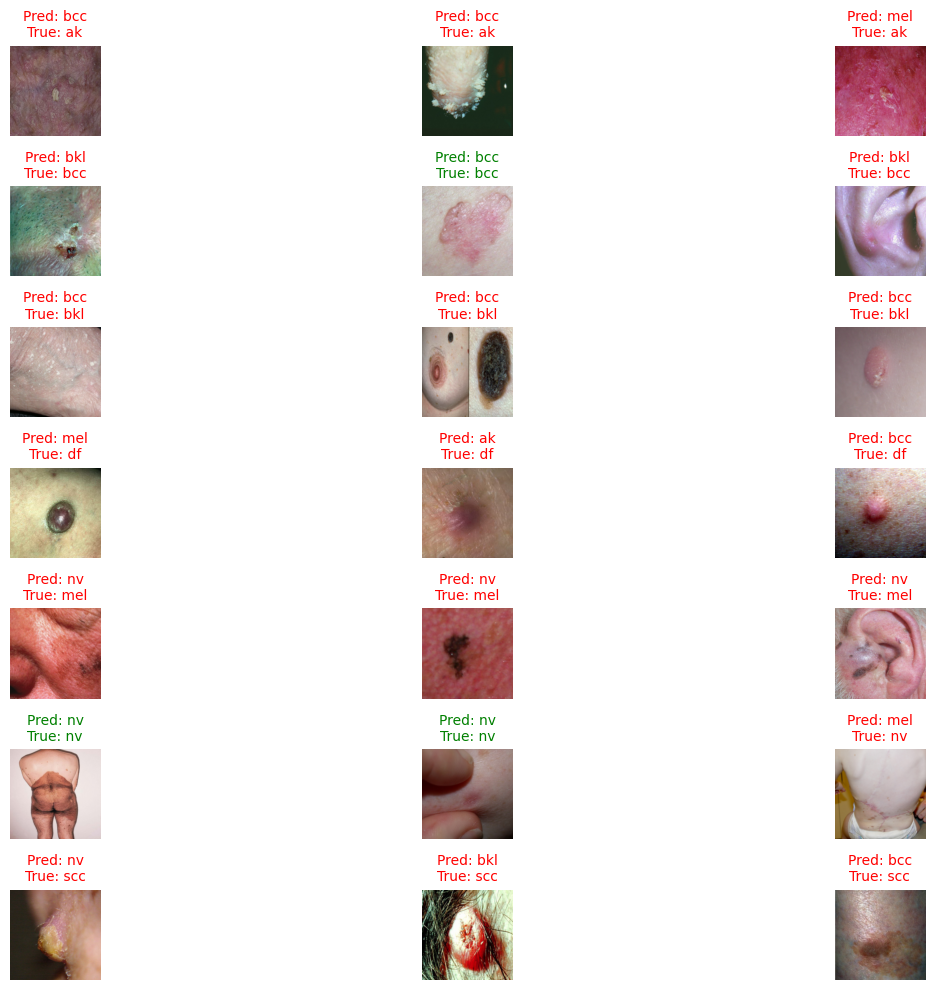

In [2]:
import torch
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import os
import sys

# Memasukkan direktori skrip ke sys.path agar bisa mengimpor arsitektur MobileNetV2
sys.path.append('/content/drive/MyDrive/Colab Notebooks/Domain Adaptation')
from adda_mobilenetV2 import get_mobilenetv2_encoder, ClassifierHead

# Path ke direktori dan model
adapt_path = "/content/drive/MyDrive/Colab Results/ADDA_MOBILENETV2/adapted.pth"
pretrain_path = "/content/drive/MyDrive/Colab Results/ADDA_MOBILENETV2/source_pretrain.pth"
test_dir = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Setup Data Uji
val_tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
test_ds = datasets.ImageFolder(test_dir, transform=val_tfm)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)
classes = test_ds.classes

# Membangun ulang kerangka MobileNetV2 dan Kepala Klasifikasi
encoder_t, feat_dim = get_mobilenetv2_encoder(pretrained=False)
classifier_s = ClassifierHead(feat_dim, len(classes))

# Memuat bobot dari DUA checkpoint yang berbeda untuk ADDA
adapt_ckpt = torch.load(adapt_path, map_location=device)
pretrain_ckpt = torch.load(pretrain_path, map_location=device)

# Memasukkan bobot ke dalam kerangka model
encoder_t.load_state_dict(adapt_ckpt['encoder_t'])
classifier_s.load_state_dict(pretrain_ckpt['classifier'])

# Memindahkan model ke GPU dan ubah ke mode evaluasi
encoder_t = encoder_t.to(device)
classifier_s = classifier_s.to(device)
encoder_t.eval()
classifier_s.eval()

# Fungsi Visualisasi
def show_predictions(encoder, classifier, dataloader, class_names, device, n_samples=1):
    samples_per_class = {cls: 0 for cls in class_names}
    shown_images = []

    with torch.no_grad():
        for imgs, labels in dataloader:
            imgs, labels = imgs.to(device), labels.to(device)
            # Ekstraksi fitur menggunakan Target Encoder, lalu tebak menggunakan Source Classifier
            feats = encoder(imgs)
            outputs = classifier(feats)
            _, preds = torch.max(outputs, 1)

            for img, pred, label in zip(imgs, preds, labels):
                cls_name = class_names[label.item()]
                if samples_per_class[cls_name] < n_samples:
                    samples_per_class[cls_name] += 1
                    shown_images.append((img.cpu(), label.item(), pred.item()))
            if all(v >= n_samples for v in samples_per_class.values()):
                break

    plt.figure(figsize=(15, 10))
    for idx, (img, label, pred) in enumerate(shown_images):
        img_np = img.permute(1, 2, 0).numpy()
        img_np = np.clip((img_np * [0.229, 0.224, 0.225]) + [0.485, 0.456, 0.406], 0, 1)
        plt.subplot(len(class_names), n_samples, idx + 1)
        plt.imshow(img_np)
        plt.axis("off")
        color = "green" if label == pred else "red"
        plt.title(f"Pred: {class_names[pred]}\nTrue: {class_names[label]}", color=color, fontsize=10)
    plt.tight_layout()
    plt.show()

# Jalankan Visualisasi
print("Showing predictions for 3 images per class...")
show_predictions(encoder_t, classifier_s, test_loader, classes, device, n_samples=3)